# Resultados: calibração da previsão de MP2,5 do CAMS em São Paulo

Este notebook reúne todos os resultados do trabalho final, na ordem de um relatório.
Cada figura vem com a pergunta que responde e a interpretação.

**Experimento.** Calibração da previsão de MP2,5 do CAMS (rodada 00 UTC, leads de 0 a 3 dias) para a **média de 5 estações CETESB** do município de São Paulo (98 Grajaú-Parelheiros, 270 Marginal Tietê, 73 Congonhas, 95 Cidade Universitária, 83 Ibirapuera). Os métodos usam só o que existe na manhã do dia previsto: a previsão do CAMS, as observações até o dia anterior e o calendário.

**Divisão.** Treino 2011–2021 (na prática 2015–2021, porque a previsão do CAMS começa em 2015), validação 2022 e teste 2023–2025, com 7 dias de intervalo entre os blocos.

**Métodos.**

| método | o que é |
|---|---|
| climatologia | média do treino para aquela época do ano |
| persistência | o MP2,5 de ontem |
| CAMS bruto | a previsão do CAMS sem correção |
| DOM | reta `obs = a + b·CAMS` ajustada nos 6 dias anteriores (Monteiro et al., 2013) |
| regressão linear | regressão com as mesmas entradas do LightGBM |
| LightGBM | árvores de decisão com gradient boosting |

**Como atualizar.** Este notebook só lê o que os scripts gravaram. Depois de mudar algo, rode, da raiz do plugin:

```bash
../Benchmark/.venv/bin/python scripts/rodar_media.py configs/benchmark_media_sp5_previsao.yaml
../Benchmark/.venv/bin/python scripts/figuras.py configs/benchmark_media_sp5_previsao.yaml
../Benchmark/.venv/bin/python scripts/sementes_tempos.py configs/benchmark_media_sp5_previsao.yaml
```

e execute o notebook de novo. Os textos de interpretação foram escritos com os resultados de 24/11/2026; se os números mudarem, confira os textos.

In [1]:
# Path: caminhos de arquivos
from pathlib import Path

# pandas: tabelas
import pandas as pd

# Image e display: mostrar figuras e tabelas no notebook
from IPython.display import Image, display

# raiz do plugin: o notebook roda de dentro de notebooks/ ou da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# pasta das figuras geradas por scripts/figuras.py
FIG = RAIZ / "figuras"
# pasta dos resultados gravados pelos scripts
RES = RAIZ / "results_media_sp5_previsao"
# nomes dos métodos em português, para as tabelas
NOMES = {
    "climatology": "climatologia",
    "persistence": "persistência",
    "forecast_raw": "CAMS bruto",
    "dom_previsao": "DOM",
    "linear_previsao": "regressão linear",
    "gbm_previsao": "LightGBM",
}
# ordem fixa dos métodos nas tabelas
ORDEM = list(NOMES.values())


def figura(nome):
    """Mostra uma figura da pasta figuras/."""
    # exibe o PNG com largura fixa
    display(Image(filename=FIG / nome, width=900))


# previsões de todos os métodos no teste
pred = pd.read_csv(RES / "predictions.csv", parse_dates=["issue_date"])
# resumo do conjunto de teste
print(
    f"amostras de teste: {pred['issue_date'].nunique()} "
    f"({pred['issue_date'].min():%d/%m/%Y} a {pred['issue_date'].max():%d/%m/%Y})"
)

amostras de teste: 756 (14/01/2023 a 28/12/2025)


---
## 1. Exploração dos dados

### 1.1 O viés da previsão do CAMS é estável no tempo?

Média mensal da observação (média das 5 estações) e da previsão bruta do CAMS para o mesmo dia (lead 0), de 2015 a 2025. As faixas cinza marcam a validação e o teste.

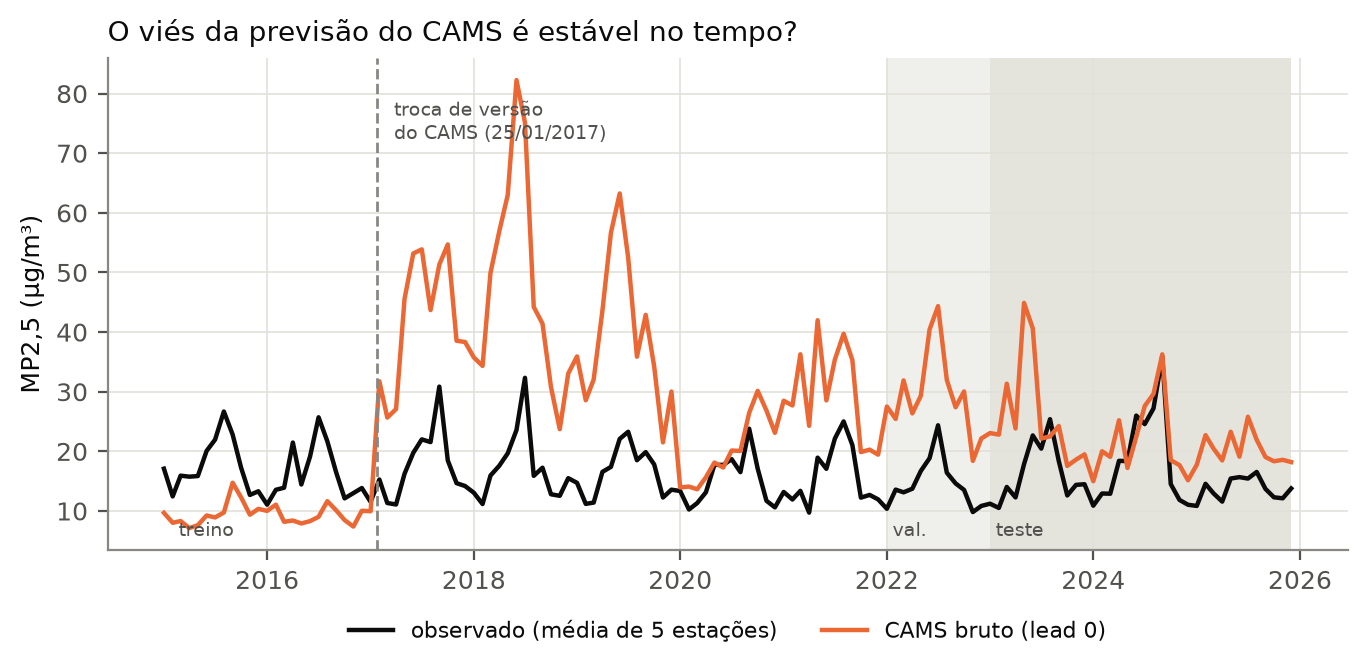

In [2]:
# figura 1: série mensal
figura("1_serie_mensal.png")

**Não.** Até janeiro de 2017 o CAMS **subestima** a observação. A partir de 25/01/2017, data de uma troca de versão do sistema do CAMS, passa a **superestimar** por um fator de 2 a 3 até 2019, e a partir de 2020 se aproxima da observação. A observação fica estável o tempo todo (média anual de 15 a 20 µg/m³).

**Consequência:** a série não é estacionária. O treino mistura regimes de viés diferentes, e o teste está em outro. Correções que se reajustam com os dias recentes (o "erro recente" das entradas e a janela do DOM) ajudam a lidar com isso.

### 1.2 O erro do CAMS é aditivo ou multiplicativo?

Diagrama de Bland-Altman no período de treino: no eixo x, a média entre observação e CAMS; no eixo y, o erro do CAMS (CAMS − observação). As linhas são a média do erro por faixa de x, separadas pela troca de versão.

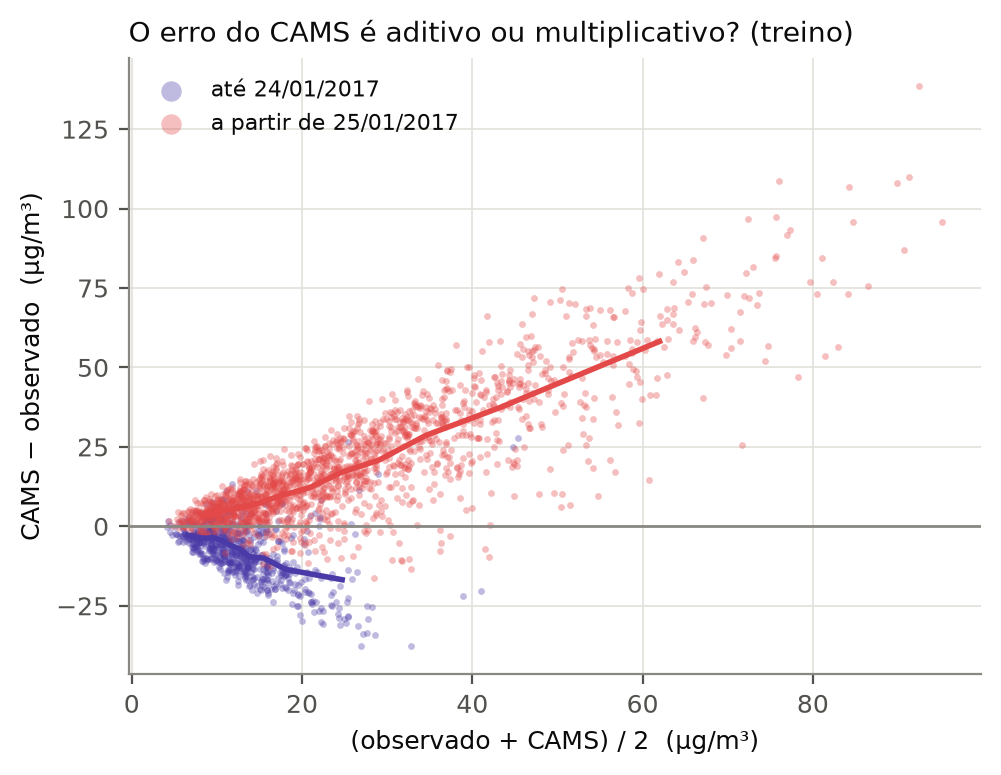

In [3]:
# figura 2: Bland-Altman
figura("2_bland_altman.png")

**Multiplicativo.** Depois de 2017, o erro cresce com o nível de poluição: quanto mais alto o MP2,5, maior a superestimativa. Um erro aditivo daria uma faixa horizontal. Isso justifica correções com termo proporcional (a inclinação `b` do DOM e o coeficiente da previsão na regressão), e não só a subtração de um viés fixo.

### 1.3 O viés depende da época do ano?

Média por mês do ano no treino: observação e CAMS antes e depois da troca de versão.

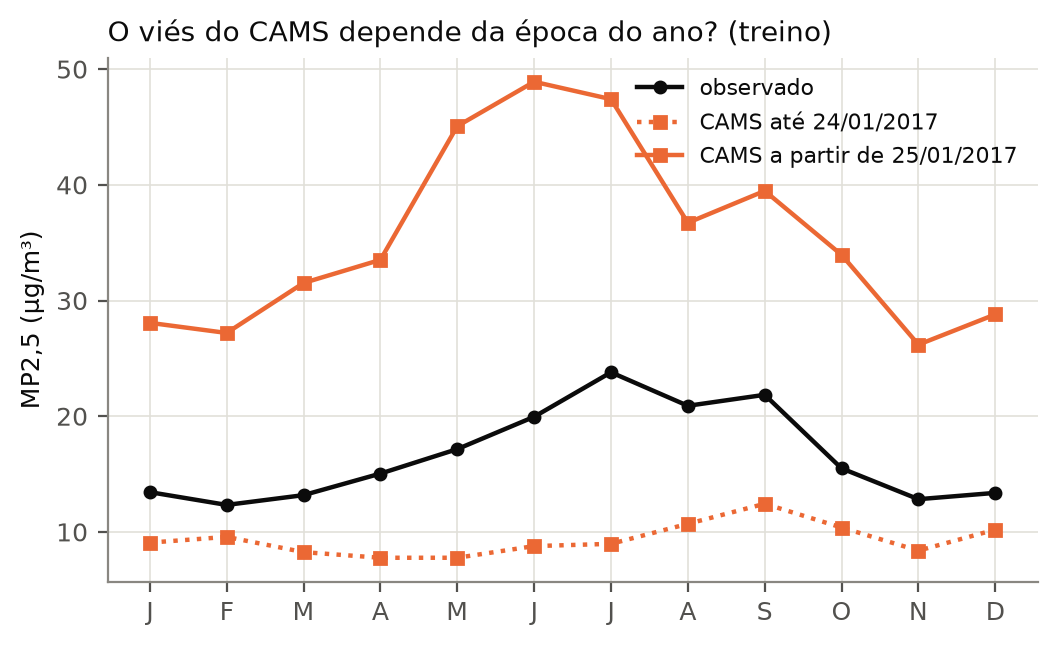

In [4]:
# figura 3: ciclo sazonal
figura("3_ciclo_sazonal.png")

**Sim.** A observação tem o pico no inverno seco (junho a setembro). O CAMS acerta a época do pico, mas depois de 2017 exagera muito a amplitude, com o maior erro justamente no inverno. Por isso a sazonalidade entra como variável dos modelos.

### 1.4 Por quantos dias o MP2,5 depende de si mesmo?

Autocorrelação da anomalia diária (observação menos a média do mês) no treino. A faixa cinza é a região de 95% de um ruído sem memória.

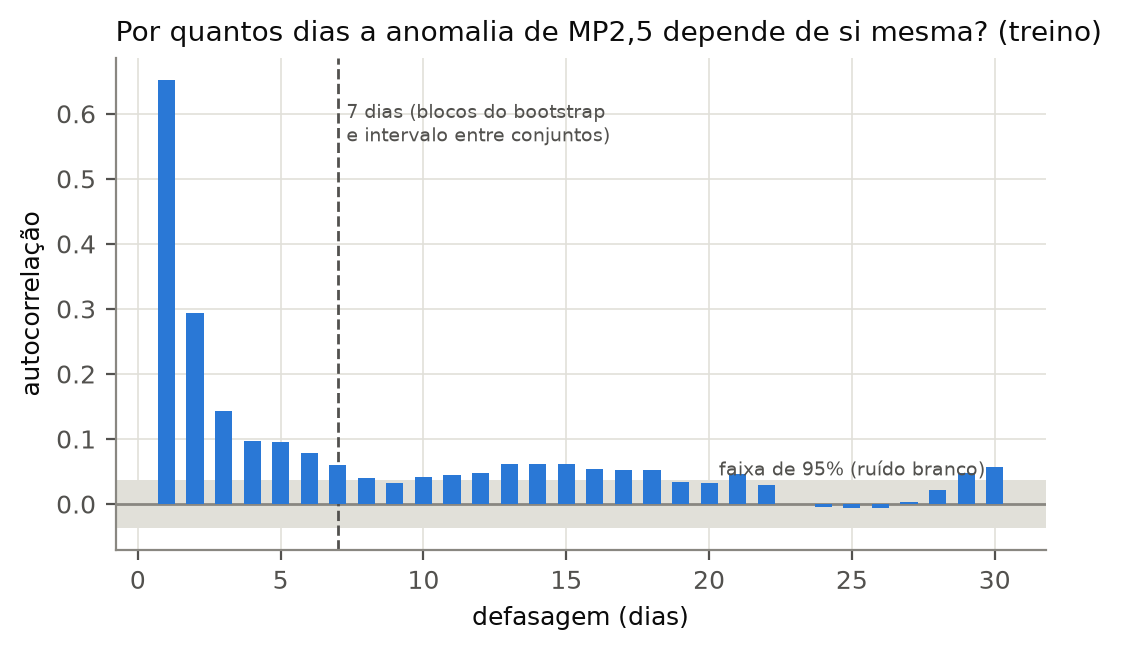

In [5]:
# figura 4: autocorrelação
figura("4_autocorrelacao.png")

A autocorrelação é alta no primeiro dia (0,65) e cai abaixo de 0,1 entre 4 e 7 dias. Isso justifica duas escolhas do protocolo: o **intervalo de 7 dias** entre treino, validação e teste, e os **blocos de 7 dias** no bootstrap (reamostrar dias isolados trataria dias vizinhos como independentes e daria intervalos de confiança estreitos demais).

---
## 2. Desempenho geral

Erro médio absoluto (MAE), raiz do erro quadrático médio (RMSE) e viés (previsão − observação) de cada método por lead, em µg/m³.

In [6]:
# métricas por método e lead gravadas pelo benchmark
scores = pd.read_csv(RES / "scores.csv")
# nomes em português
scores["método"] = scores["model"].map(NOMES)
# uma tabela por métrica: métodos nas linhas, leads nas colunas
for col, titulo in [("mae", "MAE (µg/m³)"), ("rmse", "RMSE (µg/m³)"), ("bias", "viés (µg/m³)")]:
    # tabela da métrica
    t = scores.pivot(index="método", columns="lead", values=col).loc[ORDEM].round(2)
    # título das colunas
    t.columns = [f"lead {k}" for k in t.columns]
    # mostra
    print(titulo)
    display(t)

MAE (µg/m³)


,lead 0,lead 1,lead 2,lead 3
método,,,,
climatologia,6.46,6.46,6.42,6.41
persistência,4.60,6.72,7.50,7.83
CAMS bruto,9.00,9.49,9.63,9.49
DOM,4.36,5.03,5.34,5.50
regressão linear,3.63,4.37,4.59,4.82
LightGBM,3.68,4.18,4.32,4.63


RMSE (µg/m³)


,lead 0,lead 1,lead 2,lead 3
método,,,,
climatologia,8.85,8.84,8.80,8.78
persistência,6.49,9.25,10.28,10.70
CAMS bruto,12.64,13.54,13.76,13.74
DOM,7.48,8.76,9.45,10.23
regressão linear,5.20,6.37,6.66,6.91
LightGBM,5.69,6.30,6.46,6.98


viés (µg/m³)


,lead 0,lead 1,lead 2,lead 3
método,,,,
climatologia,1.10,1.03,0.95,0.93
persistência,-0.09,-0.16,-0.23,-0.25
CAMS bruto,7.16,7.81,7.84,7.45
DOM,0.42,0.81,0.71,0.43
regressão linear,-0.12,0.07,0.10,0.04
LightGBM,-0.80,-0.73,-0.85,-0.88


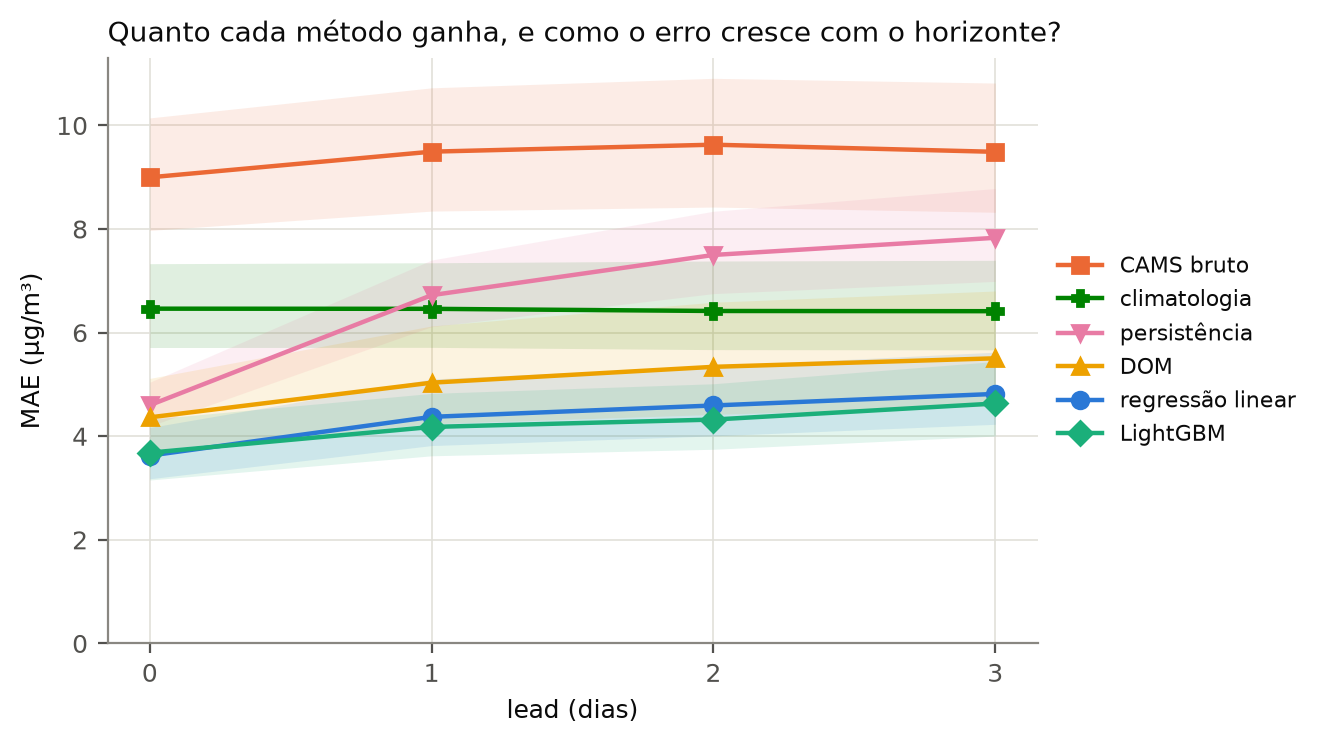

In [7]:
# figura 5: MAE por lead com IC 95%
figura("5_erro_por_lead.png")

- A **regressão linear** e o **LightGBM** têm os menores erros em todos os leads, praticamente empatados (MAE de 3,6 a 4,8 µg/m³).
- O **CAMS bruto** tem MAE de 9 a 10 µg/m³ e viés de +7 a +8: a calibração reduz o erro pela metade ou mais.
- O **DOM** fica no meio, e a **persistência** piora rápido com o lead, como esperado.
- O erro dos métodos calibrados cresce pouco do lead 0 ao 3, porque a previsão do CAMS traz informação sobre os dias futuros.

---
## 3. Hipótese: o LightGBM erra menos?

Diferença de RMSE entre cada método e o LightGBM, com intervalo de confiança de 95% por **bootstrap pareado em blocos de 7 dias**. Diferença positiva quer dizer que o LightGBM erra menos. É significativa quando o intervalo não contém zero. Os quadrados vazios repetem a conta só nos dias com observação acima do P90 do treino (dias extremos).

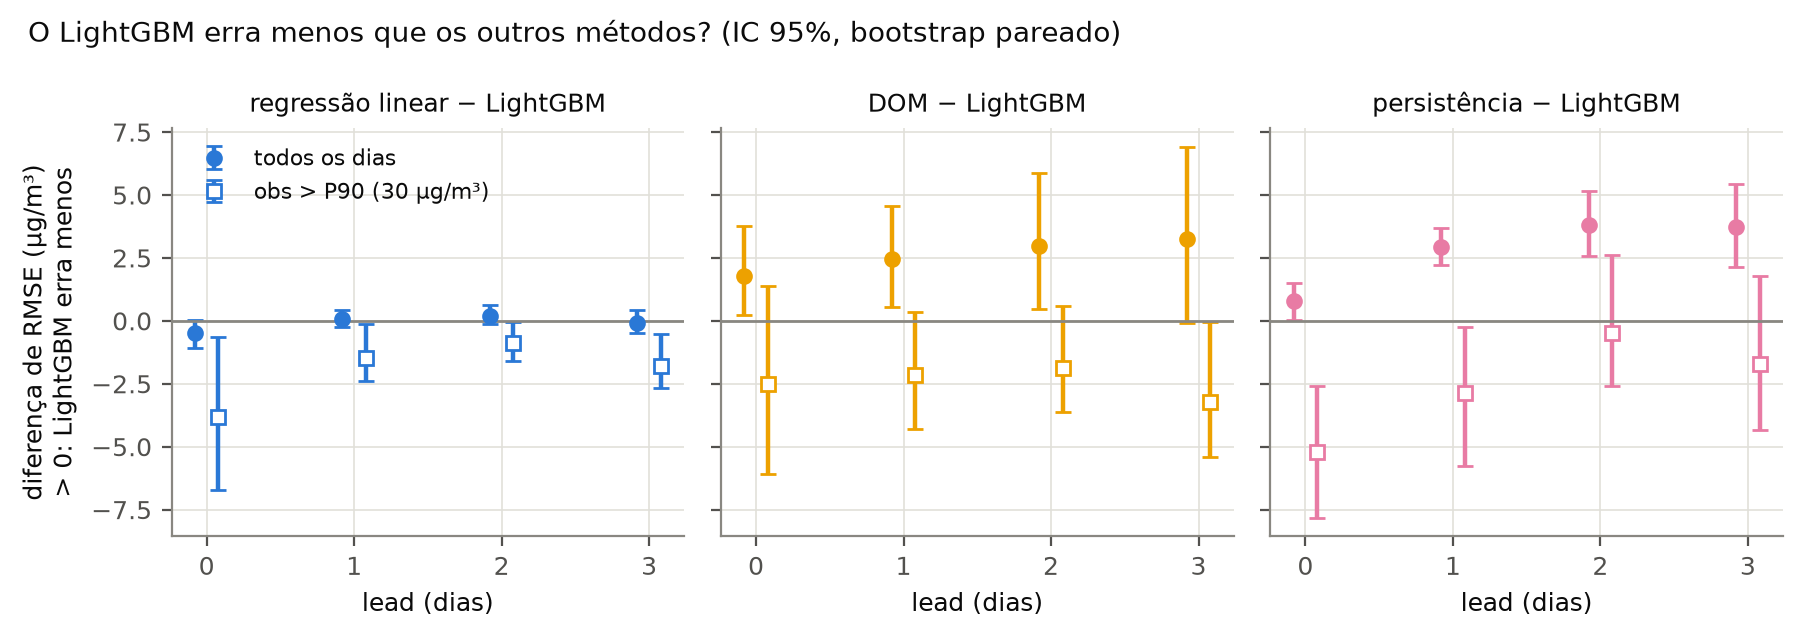

In [8]:
# figura 6: diferença pareada
figura("6_diferenca_pareada.png")

In [9]:
# tabela da figura 6
dif = pd.read_csv(RES / "diferenca_pareada.csv")
# nomes em português
dif["modelo"] = dif["modelo"].map(NOMES)
# colunas legíveis
dif = dif.rename(
    columns={
        "modelo": "método − LightGBM",
        "dif": "diferença de RMSE",
        "ic_lo": "IC 2,5%",
        "ic_hi": "IC 97,5%",
    }
)
# mostra separado por todos os dias e extremos
for dias, g in dif.groupby("dias", sort=False):
    # título
    print("todos os dias" if dias == "todos" else "só dias acima do P90 do treino")
    # tabela
    display(g.drop(columns="dias").reset_index(drop=True))

todos os dias


,método − LightGBM,lead,n,diferença de RMSE,"IC 2,5%","IC 97,5%",significativa
0,regressão linear,0,756,-0.492,-1.076,0.053,False
1,DOM,0,756,1.782,0.243,3.775,True
2,persistência,0,756,0.793,0.046,1.493,True
3,regressão linear,1,756,0.070,-0.228,0.413,False
4,DOM,1,756,2.457,0.532,4.554,True
5,persistência,1,756,2.948,2.213,3.694,True
6,regressão linear,2,756,0.198,-0.126,0.635,False
7,DOM,2,756,2.992,0.482,5.894,True
8,persistência,2,756,3.820,2.591,5.161,True
9,regressão linear,3,756,-0.068,-0.472,0.439,False


só dias acima do P90 do treino


,método − LightGBM,lead,n,diferença de RMSE,"IC 2,5%","IC 97,5%",significativa
0,regressão linear,0,54,-3.817,-6.737,-0.656,True
1,DOM,0,54,-2.513,-6.091,1.396,False
2,persistência,0,54,-5.229,-7.828,-2.574,True
3,regressão linear,1,55,-1.472,-2.408,-0.128,True
4,DOM,1,55,-2.155,-4.282,0.364,False
5,persistência,1,55,-2.881,-5.756,-0.254,True
6,regressão linear,2,55,-0.882,-1.579,-0.036,True
7,DOM,2,55,-1.861,-3.639,0.580,False
8,persistência,2,55,-0.496,-2.600,2.623,False
9,regressão linear,3,55,-1.799,-2.659,-0.522,True


**H1 (LightGBM melhor que o DOM): aceita nos leads 0, 1 e 2.** No lead 3, o intervalo encosta no zero.

**H1' (LightGBM melhor que a regressão linear com as mesmas entradas): rejeitada.** Em nenhum lead a diferença é significativa. A não linearidade não trouxe ganho sobre a regressão.

**Nos dias extremos, a relação se inverte:** a regressão linear é significativamente melhor que o LightGBM em todos os leads, e a persistência também nos leads 0 e 1. O LightGBM é o que mais subestima os picos (seção 5).

---
## 4. Skill score: quanto cada método melhora sobre uma referência?

`MSESS = 1 − MSE(método) / MSE(referência)`: 1 é a previsão perfeita, 0 erra tanto quanto a referência, negativo erra mais. Intervalos por bootstrap pareado.

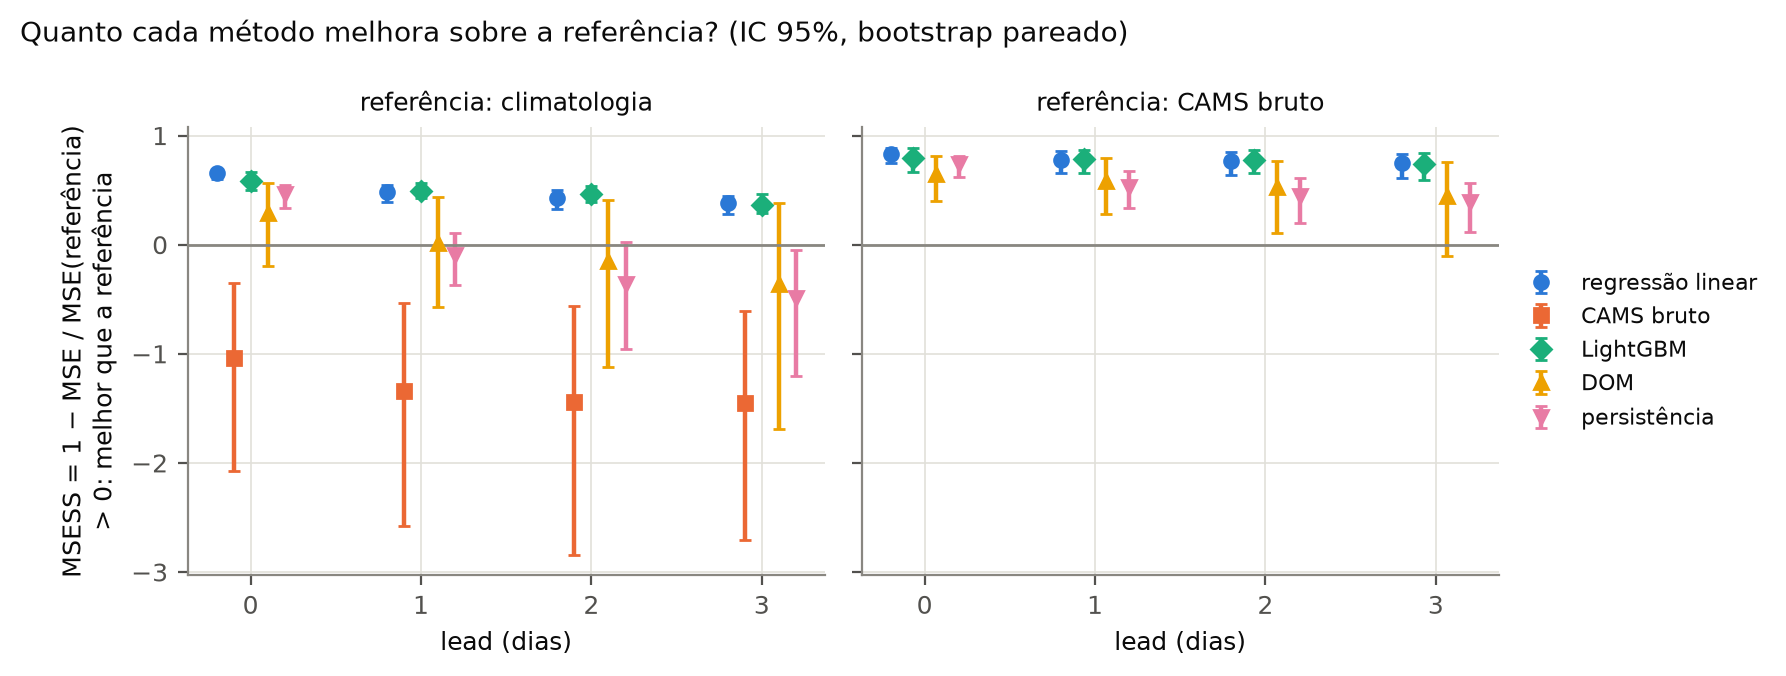

In [10]:
# figura 9: skill score
figura("9_skill_score.png")

In [11]:
# tabela do skill score
skill = pd.read_csv(RES / "skill.csv")
# nomes em português
skill["modelo"] = skill["modelo"].map(NOMES)
# referência em português
skill["referencia"] = skill["referencia"].map(NOMES)
# uma tabela por referência: métodos nas linhas, leads nas colunas
for ref, g in skill.groupby("referencia"):
    # título
    print(f"MSESS contra {ref}")
    # tabela
    t = g.pivot(index="modelo", columns="lead", values="msess").round(2)
    # colunas
    t.columns = [f"lead {k}" for k in t.columns]
    # mostra
    display(t)

MSESS contra CAMS bruto


,lead 0,lead 1,lead 2,lead 3
modelo,,,,
DOM,0.65,0.58,0.53,0.45
LightGBM,0.80,0.78,0.78,0.74
persistência,0.74,0.53,0.44,0.39
regressão linear,0.83,0.78,0.77,0.75


MSESS contra climatologia


,lead 0,lead 1,lead 2,lead 3
modelo,,,,
CAMS bruto,-1.04,-1.34,-1.44,-1.45
DOM,0.29,0.02,-0.15,-0.36
LightGBM,0.59,0.49,0.46,0.37
persistência,0.46,-0.09,-0.36,-0.48
regressão linear,0.65,0.48,0.43,0.38


- **Contra o CAMS bruto**, a regressão linear e o LightGBM removem **74 a 83% do erro quadrático**, e o DOM de 45 a 65%.
- **Contra a climatologia**, a linear e o LightGBM ganham 37 a 65%, conforme o lead.
- **O CAMS bruto é pior que a climatologia** (MSESS negativo): sem correção, prever "a média daquela época do ano" erra menos que a previsão do modelo.

---
## 5. Extremos e limiares de qualidade do ar

### 5.1 Os métodos subestimam os dias acima do P90?

Previsto contra observado nos dias com observação acima do P90 do treino (lead 1). A linha tracejada é a previsão perfeita.

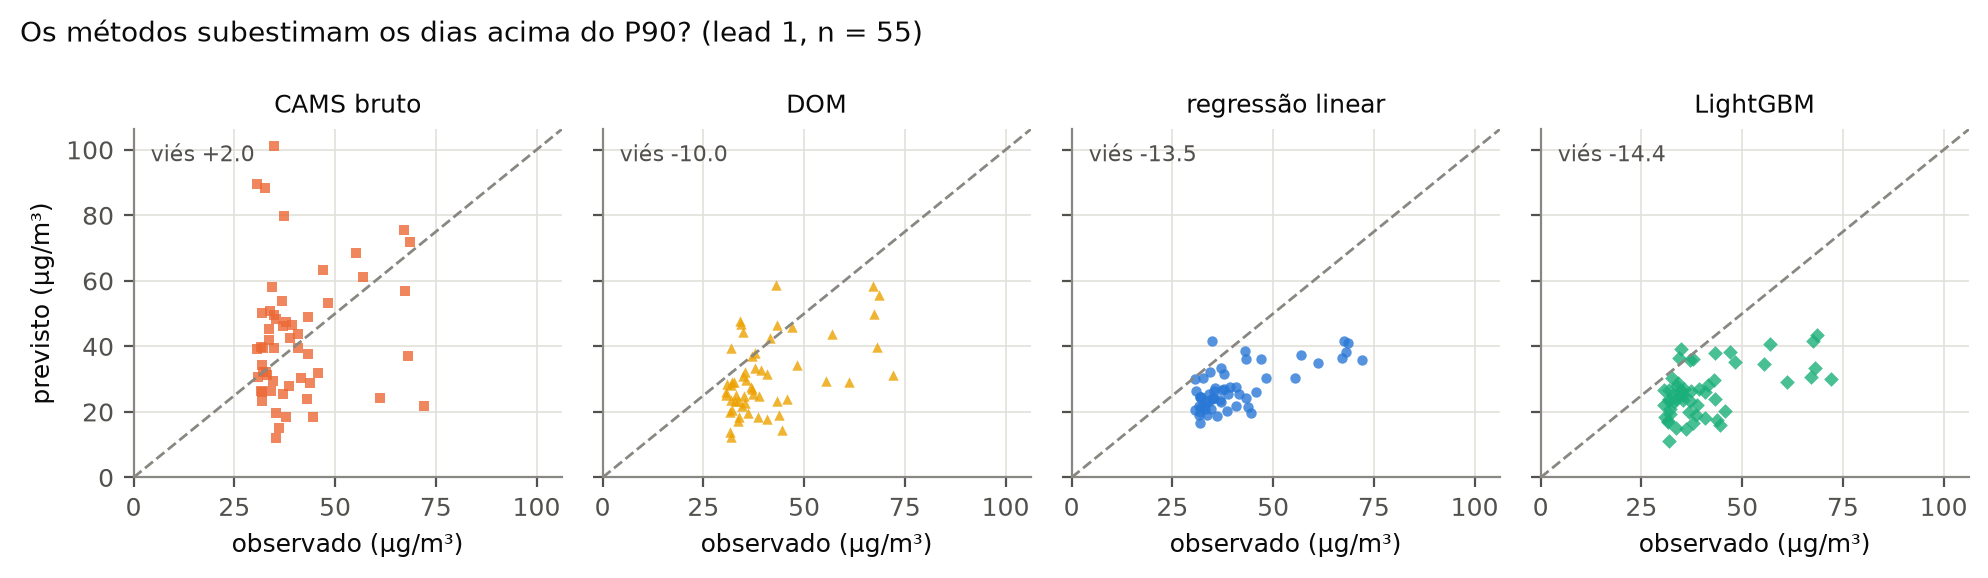

In [12]:
# figura 7: extremos
figura("7_extremos.png")

**Sim, todos os métodos calibrados.** Nos dias extremos, a regressão linear, o LightGBM e o DOM ficam bem abaixo da linha 1:1. O CAMS bruto não tem esse viés médio, mas espalha muito. Duas causas: há poucos extremos no treino, e as árvores do LightGBM não preveem valores acima dos que viram nas folhas.

### 5.2 Os métodos acertam os dias acima dos limiares?

Diagrama de desempenho (Roebber, 2009) no lead 1, para os limiares de 15 µg/m³ (diretriz diária da OMS), 25 e 50 µg/m³. O canto superior direito é a previsão perfeita; as curvas são o CSI e as retas tracejadas o viés de frequência.

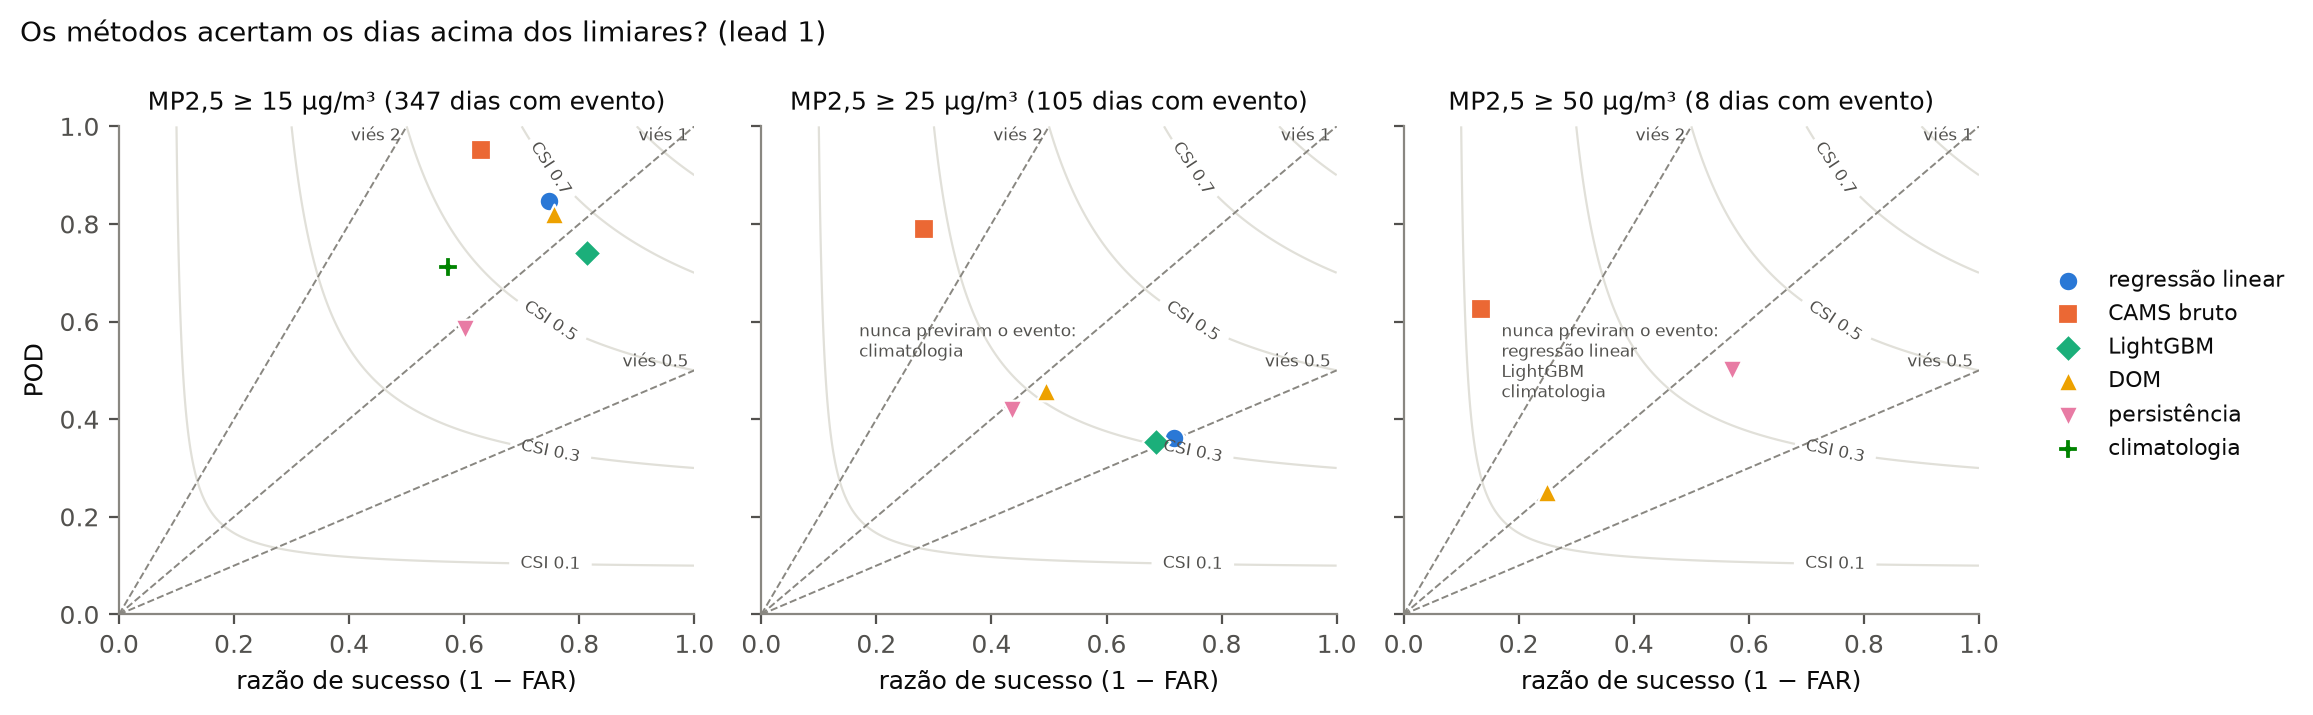

In [13]:
# figura 10: diagrama de desempenho
figura("10_diagrama_desempenho.png")

In [14]:
# métricas categóricas
cat = pd.read_csv(RES / "metricas_categoricas.csv")
# nomes em português
cat["modelo"] = cat["modelo"].map(NOMES)
# colunas mostradas
cols = [
    "modelo",
    "eventos_obs",
    "eventos_prev",
    "pod",
    "far",
    "csi",
    "ets",
    "vies_freq",
    "acuracia",
]
# uma tabela por limiar, no lead 1
for thr, g in cat[cat["lead"] == 1].groupby("limiar"):
    # título
    print(f"MP2,5 ≥ {thr:g} µg/m³, lead 1")
    # tabela
    display(g[cols].round(2).reset_index(drop=True))

MP2,5 ≥ 15 µg/m³, lead 1


,modelo,eventos_obs,eventos_prev,pod,far,csi,ets,vies_freq,acuracia
0,climatologia,347,432,0.71,0.43,0.46,0.15,1.25,0.62
1,DOM,347,377,0.82,0.24,0.65,0.42,1.09,0.80
2,CAMS bruto,347,524,0.95,0.37,0.61,0.30,1.51,0.72
3,LightGBM,347,316,0.74,0.19,0.63,0.43,0.91,0.80
4,regressão linear,347,393,0.85,0.25,0.66,0.43,1.13,0.80
5,persistência,347,338,0.58,0.40,0.42,0.15,0.97,0.63


MP2,5 ≥ 25 µg/m³, lead 1


,modelo,eventos_obs,eventos_prev,pod,far,csi,ets,vies_freq,acuracia
0,climatologia,105,0,0.00,NaN,0.00,0.00,0.00,0.86
1,DOM,105,97,0.46,0.50,0.31,0.25,0.92,0.86
2,CAMS bruto,105,294,0.79,0.72,0.26,0.15,2.80,0.69
3,LightGBM,105,54,0.35,0.32,0.30,0.26,0.51,0.89
4,regressão linear,105,53,0.36,0.28,0.32,0.27,0.50,0.89
5,persistência,105,101,0.42,0.56,0.27,0.20,0.96,0.84


MP2,5 ≥ 50 µg/m³, lead 1


,modelo,eventos_obs,eventos_prev,pod,far,csi,ets,vies_freq,acuracia
0,climatologia,8,0,0.00,NaN,0.00,0.00,0.00,0.99
1,DOM,8,8,0.25,0.75,0.14,0.14,1.00,0.98
2,CAMS bruto,8,37,0.62,0.86,0.12,0.12,4.62,0.95
3,LightGBM,8,0,0.00,NaN,0.00,0.00,0.00,0.99
4,regressão linear,8,0,0.00,NaN,0.00,0.00,0.00,0.99
5,persistência,8,7,0.50,0.43,0.36,0.36,0.88,0.99


- **15 µg/m³:** todos razoáveis; a regressão linear tem o maior CSI.
- **25 µg/m³ (105 dias com evento):** a regressão linear e o LightGBM têm poucos falsos alarmes (FAR ≈ 0,3), mas **preveem metade dos eventos que acontecem** (viés de frequência ≈ 0,5). O CAMS bruto acerta 79% dos eventos, mas 72% dos seus alarmes são falsos.
- **50 µg/m³ (só 8 dias):** a regressão linear e o LightGBM **nunca previram um evento**. Com tão poucos casos, as métricas desse limiar são muito incertas.
- **A acurácia engana com eventos raros:** no limiar de 50, a linear e o LightGBM têm a maior acurácia justamente porque nunca preveem evento e acertam todos os dias sem evento. Por isso o CSI e o POD são mais informativos.

### 5.3 Onde os métodos erram no período de teste?

Série diária no teste (lead 1): observado, regressão linear e LightGBM. As lacunas são dias sem amostra válida (faltam observações nos 6 dias anteriores ou no dia alvo).

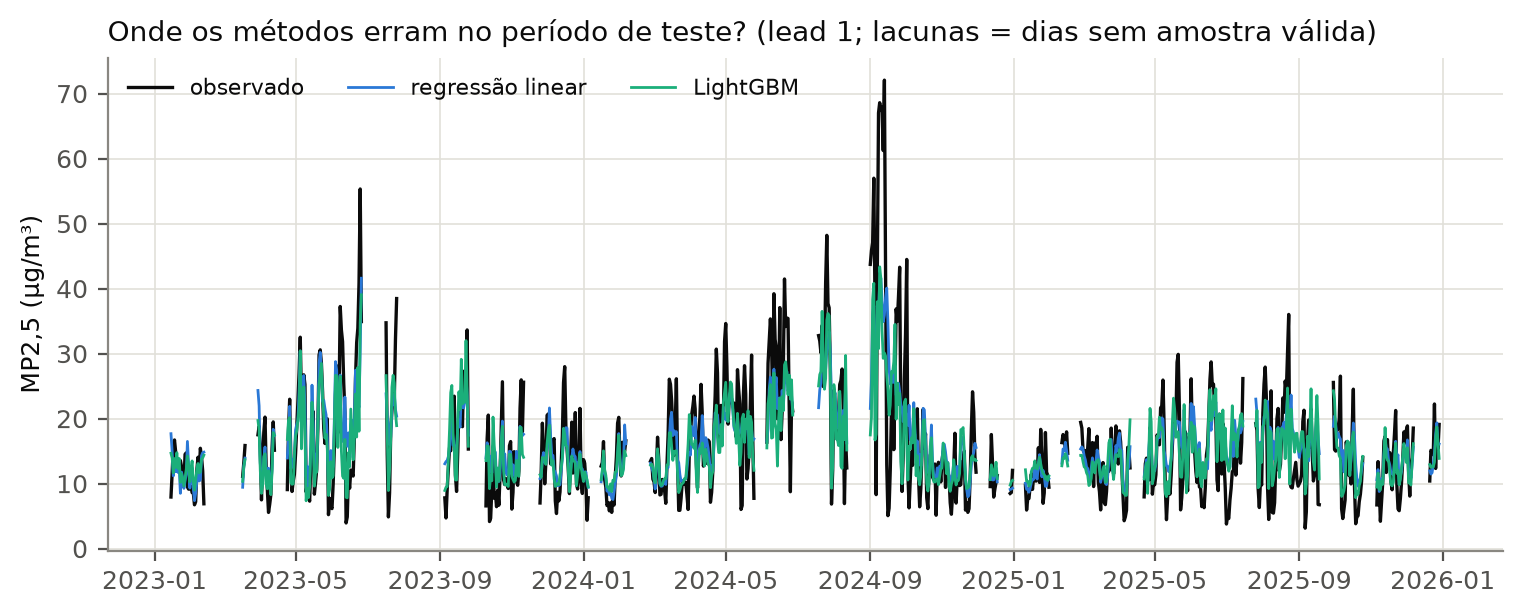

In [15]:
# figura 8: série do teste
figura("8_serie_teste.png")

Os métodos acompanham bem a variação do dia a dia, mas cortam os picos, principalmente nos episódios de inverno de 2023 e 2024 (acima de 50 µg/m³).

---
## 6. Robustez e custo operacional

### 6.1 O resultado depende da semente aleatória?

O LightGBM usado não sorteia nada no treino e **não depende da semente**: o resultado é idêntico com qualquer semente. Para medir a sensibilidade à aleatoriedade, uma variante com subamostragem (80% dos dias e 80% das variáveis por árvore) foi treinada com 10 sementes.

In [16]:
# RMSE da variante com subamostragem em cada semente
sem = pd.read_csv(RES / "sementes.csv")
# colunas de RMSE
rmse_cols = [c for c in sem.columns if c.startswith("rmse_")]
# média e desvio entre as 10 sementes
resumo = sem[rmse_cols].agg(["mean", "std", "min", "max"]).T.round(3)
# nomes das linhas
resumo.index = [f"RMSE lead {c[-1]}" for c in rmse_cols]
# nomes das colunas
resumo.columns = ["média", "desvio", "mínimo", "máximo"]
# mostra
display(resumo)

,média,desvio,mínimo,máximo
RMSE lead 0,5.649,0.037,5.586,5.707
RMSE lead 1,6.318,0.050,6.232,6.400
RMSE lead 2,6.387,0.060,6.300,6.465
RMSE lead 3,6.751,0.053,6.643,6.828


O desvio entre sementes é de 0,04 a 0,06 µg/m³, bem menor que a incerteza da amostra (os intervalos do bootstrap têm cerca de ±0,5 µg/m³). A conclusão da hipótese não depende da semente.

### 6.2 Os métodos são viáveis num sistema operacional diário?

In [17]:
# tempos de treino e de previsão
tempos = pd.read_csv(RES / "tempos.csv")
# nomes em português
tempos["modelo"] = tempos["modelo"].map(NOMES)
# colunas legíveis
tempos = tempos.rename(
    columns={
        "modelo": "método",
        "treino_s": "treino (s)",
        "previsao_ms_por_rodada": "previsão de uma rodada (ms)",
    }
)
# mostra
display(tempos.round(3))

,método,treino (s),previsão de uma rodada (ms)
0,persistência,0.000,0.024
1,climatologia,0.000,0.116
2,CAMS bruto,0.000,0.257
3,DOM,0.001,1.123
4,regressão linear,2.183,0.607
5,LightGBM,2.938,1.158


Todos são viáveis: uma previsão diária com os 4 leads custa cerca de 1 milissegundo, e o treino leva no máximo 3 segundos (Intel Xeon W-2135, 12 núcleos). Quase todo o tempo de treino da regressão e do LightGBM é a montagem das amostras em Python (cerca de 2 s), e não o ajuste.

Sobre a **dependência das observações**: os três métodos calibrados usam as observações dos 6 dias anteriores. A regressão e o LightGBM só preveem com os 6 dias completos; o DOM funciona com pelo menos 3 e, com menos, usa um fator fixo do treino, o que o torna mais robusto a falhas das estações.

---
## 7. Resumo

1. **A calibração funciona.** A previsão bruta do CAMS superestima o MP2,5 em São Paulo e erra mais que a climatologia. A calibração remove 74 a 83% do erro quadrático.
2. **O LightGBM supera o DOM** (leads 0 a 2), **mas não supera uma regressão linear com as mesmas entradas.** O método mais sofisticado não foi o melhor.
3. **Todos os métodos calibrados subestimam os extremos.** Nos dias acima do P90 a regressão linear é a menos ruim, e acima de 50 µg/m³ nem ela nem o LightGBM previram um evento.
4. **O viés do CAMS não é estacionário** (troca de versão em 2017) e é **multiplicativo**, o que explica por que correções com termo proporcional e com o erro recente funcionam bem.
5. **Todos os métodos são operacionalmente viáveis** (treino em segundos, previsão em milissegundos).